# 7-day weather forecast → wind & solar power proxies

**Question:** How much wind and solar power can we expect in Germany over the next week?
Weather drives renewable output, and renewable output drives short-term power prices.

**Steps**
1. Fetch an hourly forecast from the Open-Meteo API (free, no key)
2. Convert Unix timestamps (UTC) to local German time, DST-safe
3. Turn wind speed and irradiance into capacity factors
4. Visualise and summarise per delivery day

The reusable functions live in `weather_forecast.py`; this notebook walks through them step by step.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import weather_forecast as wf

pd.set_option("display.width", 120)
CITY = "duesseldorf"   # try "husum" for a windy coastal site

## 1. Fetch the forecast

In [2]:
lat, lon = wf.LOCATIONS[CITY]
try:
    payload = wf.fetch_forecast(lat, lon)
    print("Live data from Open-Meteo")
except requests.RequestException as err:
    payload = json.loads(wf.SAMPLE_FILE.read_text())
    print(f"Offline ({type(err).__name__}): using saved sample response")

print("Keys:", list(payload))
print("Units:", payload["hourly_units"])
print("First timestamps:", payload["hourly"]["time"][:3])

Offline (ProxyError): using saved sample response
Keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
Units: {'time': 'unixtime', 'temperature_2m': '°C', 'wind_speed_10m': 'm/s', 'wind_speed_120m': 'm/s', 'shortwave_radiation': 'W/m²'}
First timestamps: [1794614400, 1794618000, 1794621600]


## 2. Timestamp conversion: Unix seconds (UTC) → Europe/Berlin

The API returns raw Unix timestamps such as `1794614400` (seconds since 1970-01-01 UTC).
Power markets in Germany trade in **local time**, so we convert:

* `pd.to_datetime(..., unit="s", utc=True)` → timezone-aware UTC
* `.dt.tz_convert("Europe/Berlin")` → local time, CET (UTC+1) in winter, CEST (UTC+2) in summer

In [3]:
ts = payload["hourly"]["time"][0]
utc = pd.to_datetime(ts, unit="s", utc=True)
print(ts, "->", utc, "->", utc.tz_convert(wf.LOCAL_TZ))

df = wf.to_dataframe(payload)
df[["time_utc", "temperature_2m", "wind_speed_10m"]].head()

1794614400 -> 2026-11-14 00:00:00+00:00 -> 2026-11-14 01:00:00+01:00


,time_utc,temperature_2m,wind_speed_10m
time_local,,,
2026-11-14 01:00:00+01:00,2026-11-14 00:00:00+00:00,5.8,1.6
2026-11-14 02:00:00+01:00,2026-11-14 01:00:00+00:00,3.2,1.7
2026-11-14 03:00:00+01:00,2026-11-14 02:00:00+00:00,4.5,1.8
2026-11-14 04:00:00+01:00,2026-11-14 03:00:00+00:00,3.8,2.2
2026-11-14 05:00:00+01:00,2026-11-14 04:00:00+00:00,2.6,2.5


### Why not just add one hour?

Because of daylight saving time. On the last Sunday of October the clocks go back,
so that local day has **25 hours**; in March it has **23**. A fixed offset would
shift or duplicate hours. The timezone database handles it:

In [4]:
utc_hours = pd.date_range("2026-10-24 22:00", "2026-10-25 22:00", freq="h", tz="UTC")
local = utc_hours.tz_convert(wf.LOCAL_TZ)
print(pd.DataFrame({"utc": utc_hours, "local": local}).iloc[1:7])

hours_per_day = pd.Series(1, index=local).groupby(local.date).size()
print("\nHours per local day:\n", hours_per_day)

                        utc                     local
1 2026-10-24 23:00:00+00:00 2026-10-25 01:00:00+02:00
2 2026-10-25 00:00:00+00:00 2026-10-25 02:00:00+02:00
3 2026-10-25 01:00:00+00:00 2026-10-25 02:00:00+01:00
4 2026-10-25 02:00:00+00:00 2026-10-25 03:00:00+01:00
5 2026-10-25 03:00:00+00:00 2026-10-25 04:00:00+01:00
6 2026-10-25 04:00:00+00:00 2026-10-25 05:00:00+01:00

Hours per local day:
 2026-10-25    25
dtype: int64


## 3. From weather to power

**Wind**: turbines sit at ~100–150 m, where the wind is stronger than at 10 m, so we use the 120 m forecast
(if it is missing, we extrapolate from 10 m with the power law `v_h = v_10 · (h/10)^(1/7)`).
A simplified power curve maps wind speed to output:
0 below cut-in (3 m/s), cubic ramp up to rated speed (12 m/s), full output, then shutdown above 25 m/s.

**Solar**: PV output ≈ irradiance / 1000 W/m² × performance ratio (0.85).

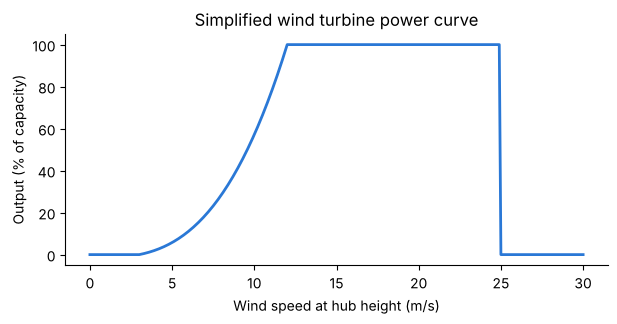

In [5]:
v = np.linspace(0, 30, 301)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(v, wf.wind_capacity_factor(v) * 100, color="#2a78d6", lw=2)
ax.set(xlabel="Wind speed at hub height (m/s)", ylabel="Output (% of capacity)",
       title="Simplified wind turbine power curve")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [6]:
df = wf.add_power_estimates(df)
df[["wind_speed_10m", "wind_hub", "wind_cf", "shortwave_radiation", "solar_cf"]].describe().round(2)

,wind_speed_10m,wind_hub,wind_cf,shortwave_radiation,solar_cf
count,168.00,168.00,168.00,168.00,168.00
mean,4.07,7.51,0.31,35.85,0.03
std,1.45,2.53,0.25,71.42,0.06
min,0.93,0.82,0.00,-1.00,0.00
25%,3.02,5.72,0.09,0.00,0.00
50%,4.20,7.82,0.26,0.00,0.00
75%,5.00,9.41,0.47,34.25,0.03
max,7.80,13.63,1.00,320.00,0.27


## 4. Results

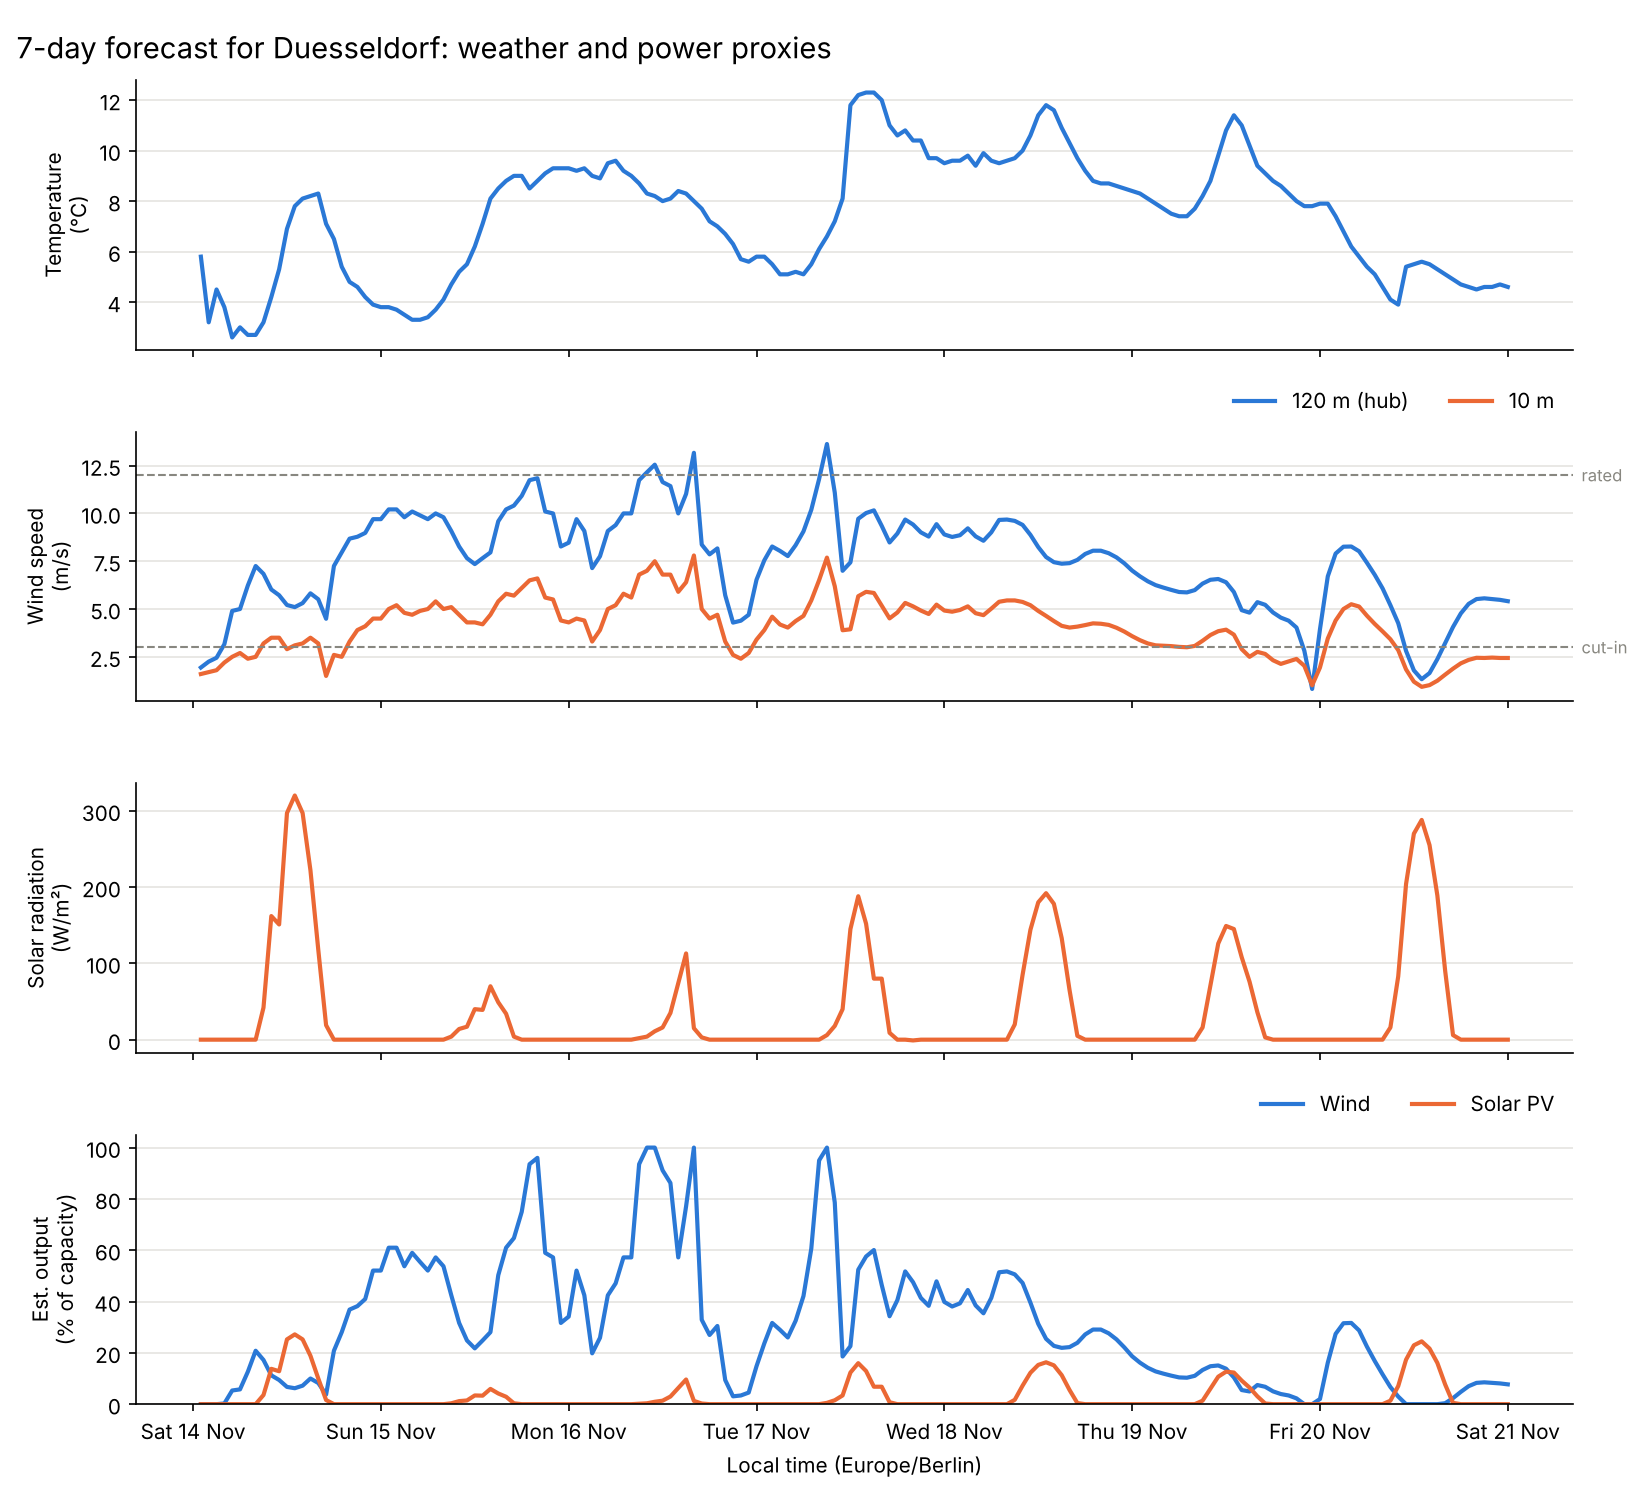

In [7]:
from pathlib import Path
from IPython.display import Image

png = wf.OUTPUT_DIR / f"forecast_{CITY}.png"
wf.OUTPUT_DIR.mkdir(exist_ok=True)
wf.plot_forecast(df, CITY, png)
Image(filename=str(png))

In [8]:
# Per local delivery day (incomplete first/last days are dropped)
wf.daily_summary(df)

,hours,temp_mean,wind_hub_mean,wind_cf,solar_cf
2026-11-15,24,6.24,9.60,0.53,0.01
2026-11-16,24,8.13,9.08,0.50,0.01
2026-11-17,24,8.51,9.16,0.46,0.03
2026-11-18,24,9.79,8.42,0.34,0.04
2026-11-19,24,8.68,5.41,0.09,0.03
2026-11-20,24,5.42,5.09,0.10,0.05


## 5. What would a trader do with this?

* **Windy days** → lots of zero-marginal-cost supply → lower day-ahead prices, sometimes negative at night.
* **Calm, cloudy days** ("Dunkelflaute") → gas plants set the price → higher prices and bigger evening peaks.
* A **battery** would charge in the cheap windy/sunny hours and discharge in the expensive calm evening hours.

This forecast is one input feature for a price model, not a price forecast itself.

## Limitations & next steps
* One location ≠ Germany: aggregate a weighted grid of points, or use installed capacity per region
* Generic power curve, no wake losses, curtailment or icing
* `shortwave_radiation` is the mean of the *preceding* hour; PV model ignores panel tilt and temperature
* Next: compare with actual generation (ENTSO-E / SMARD) and EPEX day-ahead prices, then fit a simple regression